# Hands-on 5 · Red neuronal convolucional con Fashion-MNIST

## Fundamentos

Una red neuronal convolucional (CNN) es un tipo de red neuronal artificial diseñada para identificar patrones locales en datos con una estructura espacial, como las imágenes. Sus capas convolucionales aplican filtros que se desplazan sobre la entrada y generan mapas de características que indican dónde aparecen ciertos patrones.

## Modelo Matemático

### 1. Convolucional


$$
Y_{i,j}^{(k)} =
\sum_u \sum_v \sum_c
K_{u,v,c}^{(k)} X_{i+u,j+v,c} + b^{(k)}
$$


- $X$ representa la entrada.
- $K^{(k)}$ es el filtro que genera el $k$-ésimo mapa de características.
- $u$ y $v$ recorren las posiciones del filtro y $c$ recorre los canales de entrada.
- $b^{(k)}$ es el sesgo del filtro.
- $Y_{i,j}^{(k)}$ es el valor del mapa de características en la posición $(i,j)$.

### 2. Función de activación ReLU
Introduce no linealidad en el modelo, permitiendo aprender relaciones más complejas.
$$
\operatorname{ReLU}(x)=\max(0,x)
$$

Convierte los valores negativos en cero y conserva los valores no negativos.

### 3. Capa de agrupamiento (Max pooling)

Dada una ventana local $R$, se conserva el valor máximo de la región:

$$
P = \max_{(i,j)\in R} x_{i,j}
$$

$x_{i,j}$ es el valor en la posición $(i,j)$ de la ventana. Esta operación reduce el tamaño espacial del mapa de características.



### Clasificación de salida

La capa de salida produce probabilidades sobre las clases del problema.

$$
z = Wh + b
$$

$$
\hat{y} = \operatorname{softmax}(z)
$$

- $z$ representa los *logits* o puntuaciones de las clases.
- $h$ es el vector de características que recibe la capa de salida.
- $W$ es la matriz de pesos y $b$ es el vector de sesgos.
- $\hat{y}$ es la distribución de probabilidad sobre las clases.


### Entropía cruzada categórica

La entropía cruzada categórica mide qué tan bien coinciden las probabilidades predichas por el modelo con la etiqueta real. Para una sola imagen, se calcula como:

$$
L=-\sum_{i=1}^{N}y_i\log(\hat{y}_i)
$$

- $N$ es el número de clases.
- $y_i$ es el valor de la etiqueta *one-hot* para la clase $i$. Vale 1 si es la clase real y 0 en las demás.
- $\hat{y}_i$ es la probabilidad que el modelo asigna a la clase $i$.

Como solo la clase real tiene un valor de 1 en la etiqueta, la pérdida depende de la probabilidad asignada a esa clase. Cuanto mayor sea esa probabilidad, menor será la pérdida. En esta práctica, Keras calcula esta función mediante `categorical_crossentropy`.

## Descripción de librerías, clases, funciones y parámetros

- **numpy (np)**: operaciones numéricas.
- **matplotlib.pyplot (plt) y seaborn (sns)**: visualización (histogramas, dispersión, curvas).
- **TensorFlow y Keras**: Proporcionan el dataset y las herramientas para construir, entrenar y evaluar la CNN.
- model.fit() entrena la CNN y registra la pérdida y la exactitud de entrenamiento y validación por época.
- model.evaluate() calcula la pérdida y la exactitud con el conjunto de prueba.
- model.predict() y np.argmax() obtienen las probabilidades por clase y seleccionan la clase con la probabilidad más alta.


# Pipeline

### Paso 1. Importación de librerías necesarias

Importamos las librerías de análisis y visualización, las funciones para trabajar con Fashion-MNIST y las capas de Keras que se usarán para construir la CNN.

In [1]:
# Importamos las librerías para operaciones con arreglos y visualización.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Importamos TensorFlow y el dataset Fashion-MNIST.
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist

# Importamos la función que convierte las etiquetas a formato one-hot.
from tensorflow.keras.utils import to_categorical

# Importamos el modelo secuencial y las capas que usará la CNN.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

### Paso 2. Carga del dataset Fashion-MNIST

Fashion-MNIST contiene 70 000 imágenes de 28 × 28 píxeles en escala de grises. Keras entrega 60 000 imágenes en el conjunto original de entrenamiento y 10 000 en el de prueba. Cada etiqueta es un número entero del 0 al 9 que identifica la categoría.

In [2]:
# Cargamos las imágenes y las etiquetas de entrenamiento y prueba.
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Definimos los nombres de las clases en el orden de sus etiquetas numéricas.
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


### Paso 3. Exploración de los datos

Revisamos las dimensiones de los arreglos y el rango de intensidades de los píxeles. Luego mostramos las primeras diez imágenes con sus etiquetas.

In [3]:
# Mostramos las dimensiones de las imágenes y las etiquetas.
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}")

x_train shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)
y_train shape: (60000,)


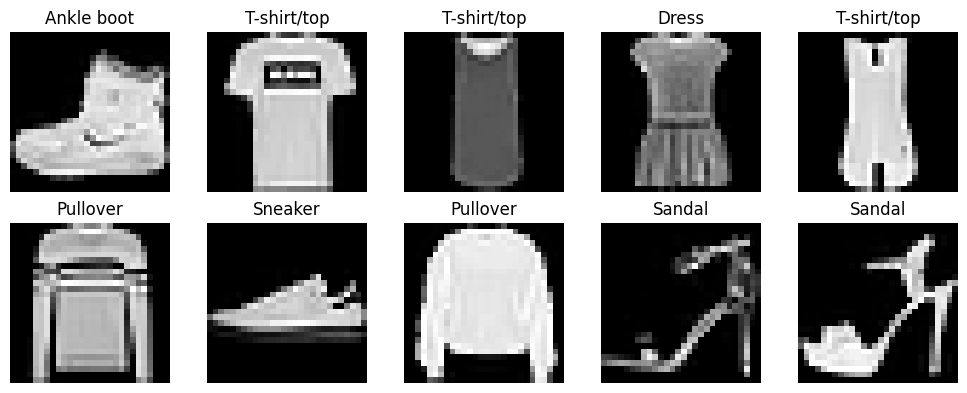

In [4]:
# Preparamos una figura para mostrar las primeras diez imágenes.
plt.figure(figsize=(10, 4))

for i in range(10):
    # Colocamos cada imagen en una cuadrícula de dos filas y cinco columnas.
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")

    # Usamos la etiqueta numérica para mostrar el nombre de su clase.
    plt.title(class_names[y_train[i]])
    plt.axis("off")

# Ajustamos la separación entre las imágenes y mostramos la figura.
plt.tight_layout()
plt.show()

### Paso 4. Preprocesamiento

1. **Normalización.** Convertimos los píxeles a `float32` y dividimos sus intensidades entre 255 para llevarlas al intervalo $[0,1]$.

   $$x_{\text{normalizado}}=\frac{x}{255}$$

2. **Dimensión del canal.** Cambiamos la forma de cada imagen de $(28,28)$ a $(28,28,1)$. El último valor indica que hay un canal de intensidad.

3. **Codificación one-hot.** Convertimos cada etiqueta en un vector de diez posiciones. Por ejemplo, la etiqueta `2`, que corresponde a Pulóver, se representa como $[0,0,1,0,0,0,0,0,0,0]$. Esta representación se usará con la entropía cruzada categórica.



In [5]:
# Normalizamos los píxeles de entrenamiento y prueba al intervalo [0, 1].
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Agregamos la dimensión del canal. El -1 conserva la cantidad de imágenes.
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Convertimos las etiquetas enteras a vectores one-hot de diez posiciones.
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

# Verificamos las formas de entrada y mostramos una etiqueta codificada.
print("Entrada de entrenamiento:", x_train.shape)
print("Entrada de prueba:", x_test.shape)
print("Etiquetas one-hot de entrenamiento:", y_train_cat.shape)
print(f"Ejemplo: {class_names[y_train[0]]} → {y_train_cat[0].astype(int)}")

Entrada de entrenamiento: (60000, 28, 28, 1)
Entrada de prueba: (10000, 28, 28, 1)
Etiquetas one-hot de entrenamiento: (60000, 10)
Ejemplo: Ankle boot → [0 0 0 0 0 0 0 0 0 1]


### Paso 5. Construcción del modelo CNN

La red usa dos bloques de convolución, ReLU y max pooling para extraer características de la imagen. Luego, `Flatten` convierte los mapas en un vector de 1 600 valores y las capas densas lo usan para clasificar la imagen en una de las diez categorías de Fashion-MNIST.

#### Flattening

`Flatten()` convierte los mapas de características de tamaño $5 \times 5 \times 64$ en un vector de 1 600 valores.

#### Dense

La primera capa densa combina las características mediante 128 neuronas
con activación ReLU. La capa densa de salida utiliza 10 neuronas con
Softmax para obtener una probabilidad por cada clase de Fashion-MNIST.

In [6]:
# Construimos la CNN en el orden en que procesa cada imagen.
model = Sequential([
    # Aplicamos 32 filtros de 3 × 3 con ReLU a la imagen de entrada.
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),

    # Reducimos el tamaño de los mapas con ventanas de 2 × 2 y paso de 2.
    MaxPooling2D(2, 2),

    # Aplicamos 64 filtros de 3 × 3 con ReLU a los mapas del primer bloque.
    Conv2D(64, (3, 3), activation='relu'),

    # Reducimos otra vez el alto y el ancho de los mapas.
    MaxPooling2D(2, 2),

    # Convertimos los mapas de características en un vector.
    Flatten(),

    # Combinamos las características en una capa de 128 neuronas con ReLU.
    Dense(128, activation='relu'),

    # Aplicamos dropout durante el entrenamiento para reducir el sobreajuste.
    Dropout(0.5),

    # Generamos una probabilidad para cada una de las diez clases.
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Paso 6 · Compilación del modelo

- **Optimizador Adam.** Actualiza los pesos y sesgos usando los gradientes calculados mediante retropropagación.
- **Entropía cruzada categórica.** Mide el error al comparar las probabilidades predichas con las etiquetas *one-hot*.
- **Exactitud (`accuracy`).** Mide la proporción de imágenes clasificadas correctamente.



In [7]:
# Configuramos Adam, la pérdida para etiquetas one-hot y la métrica de exactitud.
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

### Paso 7. Entrenamiento del modelo

Entrenamos durante **10 épocas** con lotes de hasta **64 imágenes**. Una época es un recorrido completo por las imágenes usadas para ajustar el modelo.

Con `validation_split=0.1`, Keras reserva 6 000 de las 60 000 imágenes originales para validación y usa las otras 54 000 para actualizar los parámetros. Al final de cada época calcula las métricas de validación. Las 10 000 imágenes del conjunto de prueba se reservan para la evaluación final.

In [8]:
# Entrenamos durante diez épocas y guardamos las métricas en el historial.
history = model.fit(x_train, y_train_cat,
                    epochs=10,
                    batch_size=64,
                    validation_split=0.1)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7884 - loss: 0.5889 - val_accuracy: 0.8683 - val_loss: 0.3681
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8603 - loss: 0.3968 - val_accuracy: 0.8825 - val_loss: 0.3176
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8767 - loss: 0.3456 - val_accuracy: 0.8908 - val_loss: 0.2921
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8896 - loss: 0.3079 - val_accuracy: 0.8968 - val_loss: 0.2689
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8968 - loss: 0.2864 - val_accuracy: 0.9030 - val_loss: 0.2580
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9033 - loss: 0.2672 - val_accuracy: 0.9058 - val_loss: 0.2516
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9090 - loss: 0.2511 - val_accuracy: 0.9107 - val_loss: 0.2411
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9135 - loss: 0.2381 - val_accuracy: 

### Paso 8. Evaluación del modelo

Evaluamos la CNN entrenada con las 10 000 imágenes de prueba. `evaluate()` devuelve la pérdida y la exactitud. La pérdida toma en cuenta la probabilidad asignada a la clase correcta. La exactitud indica cuántas imágenes fueron clasificadas correctamente en relación con el total:

$$
\text{Exactitud}=
\frac{\text{predicciones correctas}}{\text{total de imágenes de prueba}}
$$

In [11]:
# Obtenemos la pérdida y la exactitud sobre el conjunto de prueba.
test_loss, test_acc = model.evaluate(x_test, y_test_cat)

# Mostramos la exactitud con cuatro decimales, como en el ejemplo.
print(f"Precisión en test: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9018 - loss: 0.2761
Precisión en test: 0.9018


### Paso 9. Curvas de aprendizaje

Graficamos la exactitud y la pérdida de entrenamiento y validación en cada época. Si la pérdida de entrenamiento sigue bajando y la de validación empieza a subir, puede ser una señal de sobreajuste. Las curvas permiten ver en qué momento aparecen esas diferencias.

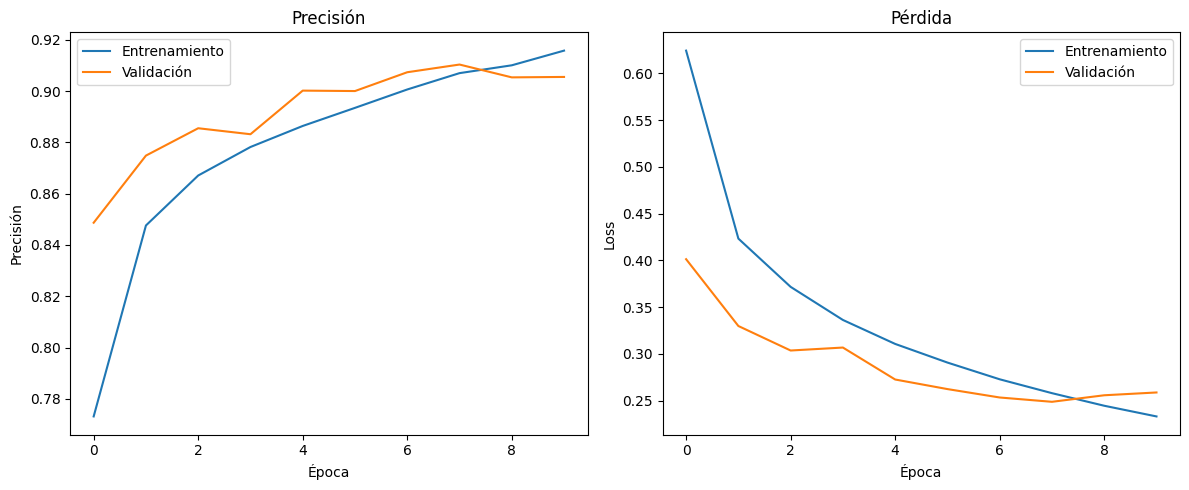

In [12]:
# Creamos una figura para colocar las dos gráficas lado a lado.
plt.figure(figsize=(12, 5))

# Graficamos la exactitud de entrenamiento y validación.
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

# Graficamos la pérdida de entrenamiento y validación.
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

# Ajustamos el espacio de las gráficas y mostramos la figura.
plt.tight_layout()
plt.show()

### Paso 10. Predicción del modelo

`predict()` devuelve diez probabilidades por imagen. Usamos `argmax()` para obtener el índice de la probabilidad mayor y buscamos el nombre de esa clase. En las primeras cinco imágenes, **P** identifica la etiqueta predicha y **R** la etiqueta real.



313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


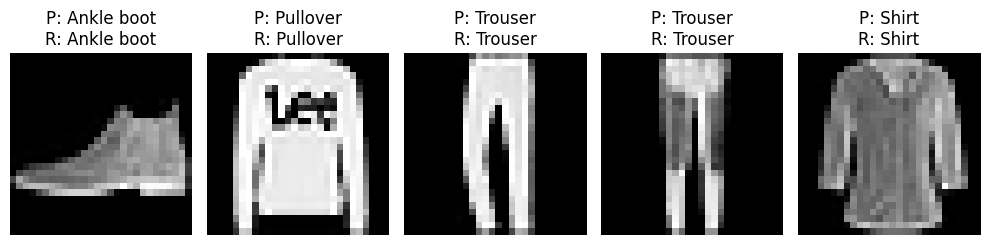

In [15]:
# Obtenemos las probabilidades de todas las imágenes de prueba.
predictions = model.predict(x_test)

# Preparamos una figura para mostrar las primeras cinco imágenes.
plt.figure(figsize=(10, 4))

for i in range(5):
    # Seleccionamos la posición y mostramos la imagen en escala de grises.
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    # Recuperamos los nombres de la clase predicha y la clase real.
    pred_label = class_names[np.argmax(predictions[i])]
    true_label = class_names[np.argmax(y_test_cat[i])]

    # Mostramos ambas etiquetas para compararlas.
    plt.title(f"P: {pred_label}\nR: {true_label}")
    plt.axis('off')

# Ajustamos la separación entre las imágenes y mostramos la figura.
plt.tight_layout()
plt.show()

### Paso 11: Precisión por clase

In [16]:
# Obtenemos las clases predichas y las clases reales.
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test_cat, axis=1)

# Mostrar informe por clase
report = classification_report(y_true_classes, y_pred_classes, target_names=class_names)
print(report)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.82      0.88      0.85      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.81      0.91      0.85      1000
       Dress       0.92      0.90      0.91      1000
        Coat       0.85      0.86      0.86      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.77      0.64      0.70      1000
     Sneaker       0.96      0.95      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.95      0.98      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



### Referencias

- Neuralthreads (2021, 02 de diciembre) Categorical cross-entropy loss — The most important loss function. https://neuralthreads.medium.com/categorical-cross-entropy-loss-the-most-important-loss-function-d3792151d05b